# Lecture 04 - Statistical Modeling: Linear & Logistic Regression Models 

* ECON/NUC_ENG-5360 

# RECAP on Pandas

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns # for visualization and dataset exploration

In [3]:
iris_df = sns.load_dataset('iris')
iris_df.head(2)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa


In [4]:
iris_df.shape

(150, 5)

In [5]:
iris_df.describe() #default numeric col summary

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [13]:
iris_df.describe(include='all')

,sepal_length,sepal_width,petal_length,petal_width,species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.057333,3.758000,1.199333,NaN
std,0.828066,0.435866,1.765298,0.762238,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


In [7]:
iris_df.species.value_counts() #count of unique species

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [8]:
# get subset of "virginica"
virginica_df = iris_df[iris_df['species'] == 'virginica']
virginica_df.shape

(50, 5)

In [7]:
# get subset of "setosa" and "setosa"
vs_df = iris_df[iris_df['species'].isin(['virginica', 'setosa'])]
vs_df.shape

(100, 5)

In [10]:
vs_df.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [12]:
# use pd.concat() to stack two sub-dataframes vertically
vs_df_1 = pd.concat([virginica_df, iris_df[iris_df['species'] == 'setosa']], axis=0) # axis = 0 is optional in this case
vs_df_1.shape

(100, 5)

In [14]:
vs_df_1.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
45,4.8,3.0,1.4,0.3,setosa
46,5.1,3.8,1.6,0.2,setosa
47,4.6,3.2,1.4,0.2,setosa
48,5.3,3.7,1.5,0.2,setosa
49,5.0,3.3,1.4,0.2,setosa


In [12]:
vs_df.equals(vs_df_1) #why? because the index is different. 

False

In [33]:
vs_df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [36]:
vs_df_1.head()

,sepal_length,sepal_width,petal_length,petal_width,species
100,6.3,3.3,6.0,2.5,virginica
101,5.8,2.7,5.1,1.9,virginica
102,7.1,3.0,5.9,2.1,virginica
103,6.3,2.9,5.6,1.8,virginica
104,6.5,3.0,5.8,2.2,virginica


In [15]:
vs_df.sort_index().head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [16]:
vs_df_1.sort_index().head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [18]:
# sort the df by index, or reset_index(drop=True) and compare again, DONE!
vs_df.sort_index().equals(vs_df_1.sort_index())   

True

# *** NEW CHARPTER ***

## Linear & Logistic Regression Models 
* Regression is the first algorithm we need to master if we are aspiring to become a data scientist. 
* It is one of the easiest statistical algorithms to learn the relationship between independent variable `X` and dependent variable `y`
  * Linear Regression Model: numeric `y`
  * Logistic Regression Model: categorical `y`

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import plotly.express as px

# Intro to statsmodels
* https://pypi.org/project/statsmodels/

In [1]:
try:
    import statsmodels.api as sm
except ImportError:
    print("statsmodels not available")
    !pip install statsmodels -U -q
    import statsmodels.api as sm

In [22]:
pip install statsmodels -U -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
graspologic 3.4.4 requires numpy<2.0.0,>=1.26.4, but you have numpy 2.5.1 which is incompatible.
graspologic 3.4.4 requires statsmodels<0.15.0,>=0.14.2, but you have statsmodels 0.15.0 which is incompatible.
autogluon-timeseries 1.5.0 requires numpy<2.4.0,>=1.25.0, but you have numpy 2.5.1 which is incompatible.
autogluon-timeseries 1.5.0 requires pandas<2.4.0,>=2.0.0, but you have pandas 3.0.6 which is incompatible.

[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
sm.__version__

'0.15.0'

# let us practice Github Repository (https://github.com/settings/education/benefits)
* use your existing Github account:
  1) create a `requirements.txt`
  2) create README
  3) create a `SRC` folder

### `statsmodels` Python Package
* A library for statistical modeling, implementing standard econometric/ statistical
models in Python using NumPy and SciPy
Includes:
    * Linear (regression) models of many forms
    * Descriptive statistics
    * Statistical tests
        
[statsmodels documentation (github)](http://github.com/statsmodels/statsmodels)

# let's get a glimpse of the dataset

In [19]:
data_str = '''Region Alcohol_Consumption Tobacco_Consumption
North 6.47 4.03
Yorkshire 6.13 3.76
Northeast 6.19 3.77
EastMidlands 4.89 3.34
WestMidlands 5.63 3.47
EastAnglia 4.52 2.92
Southeast 5.89 3.20
Southwest 4.79 2.71
Wales 5.27 3.53
Scotland 6.08 4.51
NorthernIreland 6.02 4.56'''

# data source: "An Introduction to Statistics with Python: With Applications in the Life Science"

In [20]:
#parse string to df
d = data_str.split('\n') #split by newline
d

['Region Alcohol_Consumption Tobacco_Consumption',
 'North 6.47 4.03',
 'Yorkshire 6.13 3.76',
 'Northeast 6.19 3.77',
 'EastMidlands 4.89 3.34',
 'WestMidlands 5.63 3.47',
 'EastAnglia 4.52 2.92',
 'Southeast 5.89 3.20',
 'Southwest 4.79 2.71',
 'Wales 5.27 3.53',
 'Scotland 6.08 4.51',
 'NorthernIreland 6.02 4.56']

In [21]:
#each row is a list of strings, split by a space
d = [ i.split(' ') for i in d ]
d #nested list

[['Region', 'Alcohol_Consumption', 'Tobacco_Consumption'],
 ['North', '6.47', '4.03'],
 ['Yorkshire', '6.13', '3.76'],
 ['Northeast', '6.19', '3.77'],
 ['EastMidlands', '4.89', '3.34'],
 ['WestMidlands', '5.63', '3.47'],
 ['EastAnglia', '4.52', '2.92'],
 ['Southeast', '5.89', '3.20'],
 ['Southwest', '4.79', '2.71'],
 ['Wales', '5.27', '3.53'],
 ['Scotland', '6.08', '4.51'],
 ['NorthernIreland', '6.02', '4.56']]

In [24]:
# use 1st row as column name, and other row as data 
df = pd.DataFrame(d[1:], columns=d[0])
df.head()

,Region,Alcohol_Consumption,Tobacco_Consumption
0,North,6.47,4.03
1,Yorkshire,6.13,3.76
2,Northeast,6.19,3.77
3,EastMidlands,4.89,3.34
4,WestMidlands,5.63,3.47


In [ ]:
df.info() #all string type

<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Region               11 non-null     str  
 1   Alcohol_Consumption  11 non-null     str  
 2   Tobacco_Consumption  11 non-null     str  
dtypes: str(3)
memory usage: 587.0 bytes


# convert right 2 columns to float

In [27]:
df.Alcohol_Consumption = df.Alcohol_Consumption.astype(float)
df.Tobacco_Consumption = df.Tobacco_Consumption.astype(float)

Text(0, 0.5, 'Tobacco_Consumption')

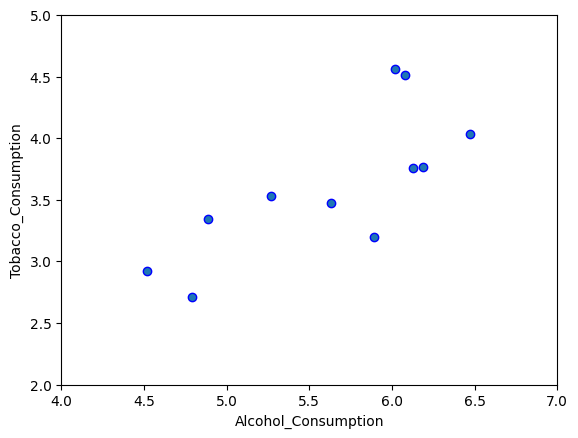

In [28]:
plt.scatter( df.Alcohol_Consumption, df.Tobacco_Consumption,
         marker='o',
         edgecolor='b' )
plt.axis([4, 7, 2, 5]) #[xmin, xmax, ymin, ymax]
plt.xlabel('Alcohol_Consumption')
plt.ylabel('Tobacco_Consumption')

# Plot indicates a linear relation between Alc and Toba consumption

**Linear regression is a common statistical technique to model the `linear relationship` between variables, Dependent Variable (DV), Independent Vairable (IV) ** DV is somethigng you want to predict, IVs are somethigng you want to use for DV prediction. 

`Ordinary Least Squares (OLS)`: linear least squares method for choosing the unknown parameters (`beta`) in a linear regression equition such that the sum of the squares of the differences between the observed DV and the output of the linear function of IV is `minimized`.

$$y = \alpha * x0 + \beta * x1 + \beta * * x2 + ......$$


## The mathmatics derivate on beta coefficient 
- @ https://web.stanford.edu/~mrosenfe/soc_meth_proj3/matrix_OLS_2_Beck_UCSD.pdf

## 3 equitions to have:
* Sum of Squares Residual/Error (SSE): $$SSE = \sum (y_i - \hat{y_i})^2 $$
* Sum of Squares Total (SST): $$SST = \sum (y_i - \bar{y_i})^2$$
* Sum of Squares Regression (SSR): $$SSR = \sum (\hat{y_i} - \bar{y_i})^2$$

#### Linear Regression model (manual calculation)

$$
\hat{y} = \hat{\beta_0} + \hat{\beta_1} x_1 + \beta_2 x_2 + \dots + \beta_n x_n)
$$


Sometime, $ \beta_0 $ is called Alpha ($ \alpha $)

**Estimation Equation**

$$
\hat{\boldsymbol{\beta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}
$$



### Example - linear relation between X (IV) and y (DV):

In [29]:
# Step 1: data generation by adding random noise to data points
np.random.seed(1234) # to make this notebook's output stable across runs

nsample = 200
X = 2 * np.random.rand(nsample, 1)
y = 4 + 3 * X + np.random.randn(nsample, 1)

In [30]:
beta0 = 4
beta1 = 3

In [31]:
print(len(X))
X[:2]

200


array([[0.3830389 ],
       [1.24421754]])

In [33]:
# check the length of X and y to ensure they are the same
len(X) == len(y)

True

In [34]:
# or use assert statement
assert len(X) == len(y), "The length of X is not the same as y"

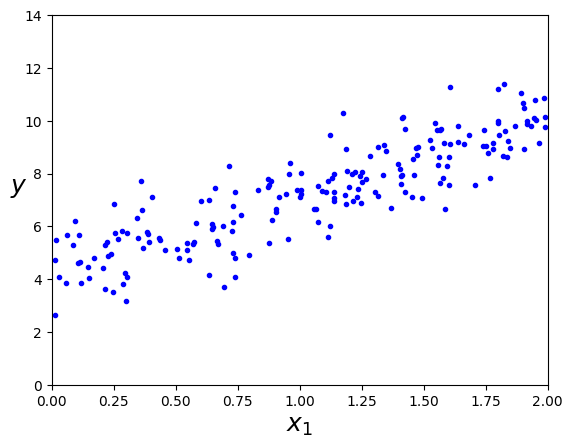

In [35]:
plt.plot(X, y, "b.") #blue dots
plt.xlabel("$x_1$", fontsize=18) #Xlabel LaTeX function 
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.axis([0, 2, 0, 14])
plt.show()

* let us refresh the knowledge of numpy `dot product` vs `matrix multiplication`

In [41]:
a = np.array([[1, 0], [0, 1]])
b = np.array([[4, 1], [2, 2]])
a.shape

(2, 2)

In [37]:
a

array([[1, 0],
       [0, 1]])

In [38]:
b

array([[4, 1],
       [2, 2]])

In [40]:
np.dot(a, b) 

# 4 = 1 * 4 + 0 * 2
# 1 = 1 * 1 + 0 * 2
# ... 

array([[4, 1],
       [2, 2]])

In [42]:
np.dot(a, b) #or a @ b, row to column multiplication then sum 

array([[4, 1],
       [2, 2]])

In [43]:
np.multiply(a, b) #pairwise multiplication

array([[4, 0],
       [0, 2]])

# use python code to get '$ \beta $'

In [6]:
np.random.seed(1234) # to make this notebook's output stable across runs
nsample = 200
X = 2 * np.random.rand(nsample, 1)
y = 4 + 3 * X + np.random.randn(nsample, 1)

In [7]:
X[:2]

array([[0.3830389 ],
       [1.24421754]])

In [8]:
y[:2]

array([[5.77789253],
       [7.91914698]])

In [10]:
# Stack 1-D arrays as columns into a 2-D array. np.c_ short for np.concatenate
np.c_[np.ones((nsample, 1)), X][:5]

array([[1.        , 0.3830389 ],
       [1.        , 1.24421754],
       [1.        , 0.87545548],
       [1.        , 1.57071717],
       [1.        , 1.55995162]])

In [11]:
np.concatenate([np.ones((nsample, 1)), X], axis = 1)[:5]

array([[1.        , 0.3830389 ],
       [1.        , 1.24421754],
       [1.        , 0.87545548],
       [1.        , 1.57071717],
       [1.        , 1.55995162]])

In [12]:
X_b = np.c_[np.ones((nsample, 1)), X] # np.concatenate([np.ones((nsample, 1)), X], axis = 1).shape 
# concatenate by axis=1 with x0 = 1 as the 1st column, which will be used form x0 * beta0
print(X_b[:2])

[[1.         0.3830389 ]
 [1.         1.24421754]]


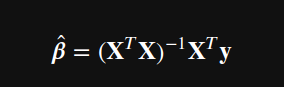

In [14]:
X_new = np.array([0,2]) #new data with 2 values for X
print(X_new)

[0 2]


In [15]:
#create input with `$beta0` of 1 
X_new_b = np.c_[np.ones((2, 1)), X_new]  # add x0 = 1 to each instance by np.c_
#print(f"To be predicted matrix {np.array(X_new_b)}")
X_new_b


array([[1., 0.],
       [1., 2.]])

In [17]:
beta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y) #  [0][0]}, and the beta_1 is {beta_best[1][0]}')
beta_best

array([[4.21637888],
       [2.91452187]])

In [18]:
y_predict = X_new_b.dot(beta_best)
y_predict

array([[ 4.21637888],
       [10.04542261]])

In [19]:
X_new

array([0, 2])

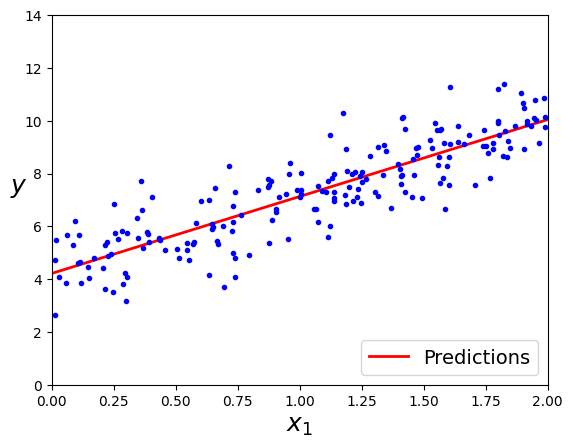

In [20]:
plt.plot(X_new, y_predict, "r-", linewidth=2, label="Predictions")
plt.plot(X, y, "b.")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.legend(loc="lower right", fontsize=14)
plt.axis([0, 2, 0, 14]) #xmin = 0, xmax = 4, ymin = 0, ymax = 14 
# plt.savefig('My first linear regression')
plt.show()

## Fit Linear Regression model using `statsmodels.api`

In [21]:
import statsmodels.api as sm

In [22]:
X_const = sm.add_constant(X) #equivalent to X_b
X_const[:10]

array([[1.        , 0.3830389 ],
       [1.        , 1.24421754],
       [1.        , 0.87545548],
       [1.        , 1.57071717],
       [1.        , 1.55995162],
       [1.        , 0.54518521],
       [1.        , 0.55292851],
       [1.        , 1.60374436],
       [1.        , 1.91627871],
       [1.        , 1.75186527]])

In [23]:
model = sm.OLS(y,X_const).fit()
#model = OLS_model.fit()
model.summary() #it looks like SAS wholesale output, doesn't it, LOL

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.758
Model:                            OLS   Adj. R-squared:                  0.757
Method:                 Least Squares   F-statistic:                     620.8
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           6.00e-63
Time:                        14:12:00   Log-Likelihood:                -272.00
No. Observations:                 200   AIC:                             548.0
Df Residuals:                     198   BIC:                             554.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.2164      0.140     30.024      0.000       3.939       4.493
x1             2.9145      0.117     24.916      0.000       2.684       3.145
==============================================================================
Omnibus:                        0.510   Durbin-Watson:                   1.840
Prob(Omnibus):                  0.775   Jarque-Bera (JB):                0.303
Skew:                           0.082   Prob(JB):                        0.859
Kurtosis:                       3.096   Cond. No.                         4.01
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [24]:
model = sm.OLS(y,X_const).fit()

In [25]:
print(type(model.summary()))
model.summary2().tables[1]

<class 'statsmodels.iolib.summary.Summary'>


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,4.216379,0.140433,30.024137,1.228086e-75,3.939443,4.493315
x1,2.914522,0.116976,24.915565,6.004805e-63,2.683843,3.145200


In [26]:
#model.summary2().tables[1] #p-value, pls google it, you would like to see the p-value is less than a threshold (significance) of 0.05 

In [27]:
model.summary2().tables[2]

,0,1,2,3
0,Omnibus:,0.510,Durbin-Watson:,1.840
1,Prob(Omnibus):,0.775,Jarque-Bera (JB):,0.303
2,Skew:,0.082,Prob(JB):,0.859
3,Kurtosis:,3.096,Condition No.:,4


## LR Model performance
- R-squared: higher, better, Higher `R2` mean the model can explain the variance of y by r2 (percentage).
- Adj R-squared: take observation number of X into account @ https://www.graphpad.com/guides/prism/latest/curve-fitting/reg_adjusted-r-squared.htm
- AIC and BIC should be as smaller as possible

In [28]:
len(model.summary2().tables)

3

In [29]:
type(model.summary2())

statsmodels.iolib.summary2.Summary

In [30]:
model.summary2().tables[1]

,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,4.216379,0.140433,30.024137,1.228086e-75,3.939443,4.493315
x1,2.914522,0.116976,24.915565,6.004805e-63,2.683843,3.145200


### Using models to make predictions

In [31]:
X_new_b

array([[1., 0.],
       [1., 2.]])

In [32]:
model.predict(X_new_b)

array([ 4.21637888, 10.04542261])

### get model Coefficients

By minimizing SSE/MSE (cost/object function) we get
$$
\hat{\boldsymbol{\theta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}
$$

In [33]:
model.params #get coefficients

array([4.21637888, 2.91452187])

### Standard Error of Coefficients to see if the coefficient is significant
$
CE = ({X}^T {X})^{-1} * \sigma^2  
$
#matrix multiplication

In [34]:
X_const.shape

(200, 2)

In [35]:
# convert the NumPy arrray to matrix
X = np.matrix(X_const) #X_const is 2D array
X[:5]

matrix([[1.        , 0.3830389 ],
        [1.        , 1.24421754],
        [1.        , 0.87545548],
        [1.        , 1.57071717],
        [1.        , 1.55995162]])

In [38]:
# perform the matrix multiplication and then take the inverse of it
CE = np.linalg.inv(X.T.dot(X)) 
CE.shape

(2, 2)

# mean squared error (mse)

In [39]:
model.mse_resid

np.float64(0.8978053754947755)

In [40]:
CE = CE * model.mse_resid

In [41]:
# multiply by the MSE of the residual (sigma^2)
# #"mse" for mean square error
print(CE.shape)
CE #close enough!

(2, 2)


matrix([[ 0.01972142, -0.01443712],
        [-0.01443712,  0.01368337]])

In [42]:
np.sqrt(4) == 2

np.True_

# std = squared root of variance/sigma_square/

In [43]:
# take the square root of diagnal values of CE and round it to 3 decimal
SE = np.round(np.sqrt(np.diag(CE)), 3) 
print(SE)

[0.14  0.117]


### T-statistic and P-value

A `t-statistic` measures how different our estimation from 0 given the data that we are using. The t-statistic can be translated into a p-value (a probability).

### **The P-value is the likelihood (probability) that the null hypothesis is true given the sample that we have collected.**

In our case, since the p-value is greater than `.05` (default significance test level) we will fail to reject the null hypothesis. that is, the coefficient $\beta$ is significant for the model.

## Evaluating Model Performance

### $R^{2}$ and Adjusted $R^{2}$ - is the model performance good enough? 

The $R^{2}$ term is the coefficient of determination and it usually reflects how well the model fits the observed data. 
The coefficient of determination is usually given by:

$$R^2 = 1 - \frac{SSE}{SST}$$

Where $y_{i}$ is an observed response, $\bar{y}$ is the mean of the observed responses, $\hat{y_{i}}$ is a prediction of the response made by the linear model, and $(y_{i} - \hat{y_{i}})$ is the residual, i.e., the difference between the response and the prediction. Also, SSE is called the sum of the squared error, or SSR the sum of the squared residuals, and SST is called the total sum of squares.

$$adjusted \  R^2 = 1 - \frac{(1-R^2)*(n-1)}{(n-p)}$$


where n is the number of data/obsevation and p the number of parameters or variables

In [44]:
SSE = model.mse_resid * nsample #sum of the squared error
print(SSE)
SST = sum(np.square(y - np.mean(y))) #total sum of squares
print(SST)
r_square = 1 - SSE/SST
print(r_square.item(), model.rsquared) #compare calcualted r-square with sm output, they are close enough to each other.

179.5610750989551
[735.10992533]
0.7557357492912357 0.7581783917983234


### Log-Likelihood

A probability density function is a function of x, your data point, and it will tell you how likely it is that certain data points appear. A likelihood function, on the other hand, takes the data set as a given, and represents the likeliness of different parameters for your distribution.

$$p(D\; | \;  \pmb \theta\;) \\\\
= p(\pmb x_1 \; | \; \pmb \theta\;)\; \cdot \; p(\pmb x_2 \; | \;\pmb \theta\;) \; \cdot \;...  \; p(\pmb x_n \; | \; \pmb \theta\;) \\\\
= \prod_{k=1}^{n} \; p(\pmb x_k \pmb \; | \; \pmb \theta \;)$$

$$\\
\Rightarrow l(\theta) = \sum_{k=1}^{n} ln \; p(x_k|\theta)$$

In [45]:
N = model.nobs #number of observations

SSR = model.ssr

s2 = SSR / N

#given a "strong" assumption that error term has zero
#mean with constant variance, it also follows normal distribution
L = (1.0/np.sqrt(2*np.pi*s2)) ** N * np.exp(-SSR/(s2*2.0)) 

print ('ln(L) =', round( np.log(L),2))

ln(L) = -272.0


For more to reference about log-likelihood: https://www.stat.cmu.edu/~cshalizi/mreg/15/lectures/06/lecture-06.pdf

### AIC and BIC - how a model is better than the others

The Akaike information criterion (AIC) and the Bayesian information criterion (BIC) are based on the log-likelihood described in the previous section. Both measures introduce a penalty for model complexity, but the AIC penalizes complexity less severely than the BIC. The AIC and BIC are given by:

$$AIC = 2*(p+1)-2*l(\theta)$$
$$BIC = (p +1)*ln(N)-2*l(\theta)$$

In [81]:
AIC = 2 * (model.df_model+1) - 2 * np.log(L)
BIC = np.log(nsample) * (model.df_model+1) - 2 * np.log(L)
print(AIC,BIC) #the lower, the better

548.0049530622945 554.6015877953905


## AIC and BIC, R squared values are 2 important model performance matrices. 

### t-Statistic

The t-test is used to test the null hypothesis that coefficient of a given variable is zero. Usually it is tested at $\alpha$ = 0.05 or 0.001. If Pr(T $\geq$ |t|) < $\alpha$, we reject null hypothesis that the variable is a significant variable for the model. 

\begin{align*} t_i = \beta_i/SE_i,_i\end{align*}

In [82]:
for i in range(2):
    beta = model.params[i]
    se = SE[i]
    t= beta/se
    print("t-Statistic for beta_%s is "%i, t) #

t-Statistic for beta_0 is  30.1169919676255
t-Statistic for beta_1 is  24.910443321726863


In [83]:
(model.summary2().tables[1]).t #close enough !

const    30.024137
x1       24.915565
Name: t, dtype: float64

# Logistic regression (predict a binary outcome with probilities)

### We know (left chart) is linear regression,  (right chart) is new...

Logistic regression Examples:
* Going vacation or not
* Mail customers (coupons, ads...)
* Fraud or not Fraud/Spam or not Spam
* ...

# Logistic regression

## 1. Concepts

**Logistic Regression model estimated probability in vectorized form **

<center><img src="https://bookdown.org/cuborican/RE_STAT/LV_1.png" width="850" height="600" /></center>
<center><img src="https://miro.medium.com/v2/resize:fit:640/format:webp/1*a2e-ozEcNCm_s0trFzf-DA.jpeg" width="850" height="600" /></center>

$$ln \frac{p}{1-p} = {\theta}^T \mathbf{x}$$

**or**
$$
p = \sigma(\boldsymbol{\theta}^T \mathbf{x})    ,\      \sigma(t) = \dfrac{1}{1 + \exp(-t)}$$

Some case it is call "Sigmoid function" @  https://en.wikipedia.org/wiki/Sigmoid_function

**Logistic Regression model prediction**

$$
\hat{y} =
\begin{cases}
  0 & \text{if } \hat{p} < 0.5, \\
  1 & \text{if } \hat{p} \geq 0.5.
\end{cases}
$$

### Now it is about the parameters $\theta$
### Remeber this?

$
\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_n x_n
$



**Estimation Equation**

$
\hat{\boldsymbol{\theta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}
$





### Training and Cost Function for logistic regression (Optional Slides)
Details in derivate @ https://medium.com/analytics-vidhya/derivative-of-log-loss-function-for-logistic-regression-9b832f025c2d



**Cost function of a single training instance**

$$
c(\boldsymbol{\theta}) =
\begin{cases}
  -\log(\hat{p}) & \text{if } y = 1, \\
  -\log(1 - \hat{p}) & \text{if } y = 0.
\end{cases}
$$


**Logistic Regression cost/loss function (log loss)**

$$
J(\boldsymbol{\theta}) = -\dfrac{1}{m} \sum\limits_{i=1}^{m}{\left[ y^{(i)} log\left(\hat{p}^{(i)}\right) + (1 - y^{(i)}) log\left(1 - \hat{p}^{(i)}\right)\right]}
$$

The bad news is that there is no known `closed-form` equation to compute the value of $θ$ that minimizes this cost function (there is no equivalent of the Linear Equation).
But the good news is that this cost function is convex, so it is guaranteed to find the global minimum. The partial derivatives of the cost function with regards to the jth model parameter $\theta_j$ is given by

**Logistic cost function partial derivatives**

$$
\dfrac{\partial}{\partial \theta_j} \text{J}(\boldsymbol{\theta}) = \dfrac{1}{m}\sum\limits_{i=1}^{m}\left(\mathbf{\sigma(\boldsymbol{\theta}}^T \mathbf{x}^{(i)}) - y^{(i)}\right)\, x_j^{(i)}
$$


## Logistic regression Example 1

### Pima diabete data @ 
- [Kaggle Data Source](https://www.kaggle.com/uciml/pima-indians-diabetes-database) or 
- [Network Repo](https://nrvis.com/data/mldata/pima-indians-diabetes.csv)

# multiclass regression (logitclass)
* Multinomial logistic regression, also known as multinomial logit (mlogit)

In [46]:
!unzip pima.zip

Archive:  pima.zip
  inflating: diabetes.csv            


In [47]:
# load dataset
pima = pd.read_csv("./diabetes.csv")#, names=col_names)

In [48]:
pima.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [49]:
pima.shape

(768, 9)

In [50]:
pima.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [22]:
col_names = ["Pregnancies","Glucose","BloodPressure","Insulin","BMI","Age","Outcome"] #'skin',?

In [17]:
pima = pima.loc[:, col_names]
pima.head()

,Pregnancies,Glucose,BloodPressure,Insulin,BMI,Age,Outcome
0,6,148,72,0,33.6,50,1
1,1,85,66,0,26.6,31,0
2,8,183,64,0,23.3,32,1
3,1,89,66,94,28.1,21,0
4,0,137,40,168,43.1,33,1


In [18]:
pima.shape

(768, 7)

In [20]:
pima.Outcome.value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

### Selecting Feature (Independent variables)
Here, you need to divide the given columns into two types of variables dependent(or target variable) and independent variable(or feature variables).

In [23]:
#split dataset in features and target variable
feature_cols = col_names[:-1]
X = pima[feature_cols] # Features
y = pima.Outcome # Target variable

In [24]:
X.head()

,Pregnancies,Glucose,BloodPressure,Insulin,BMI,Age
0,6,148,72,0,33.6,50
1,1,85,66,0,26.6,31
2,8,183,64,0,23.3,32
3,1,89,66,94,28.1,21
4,0,137,40,168,43.1,33


In [25]:
type(y)

pandas.core.series.Series

In [26]:
y.value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

## Good Practice on model data preparation 
## Split data into two kinds of data: in-sample vs out-of-sample 

### Let us Splitting Data
To understand model performance, dividing the dataset into a training set and a test set is a good strategy.

Let's split dataset by using function `train_test_split()`. You need to pass 3 parameters `features(Xs)`, `target`, and `test_set size`. Additionally, you can use `random_state` to select records randomly.

In [27]:
# scikit-learn 

In [28]:
pip install scikit-learn -U

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 14.8 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
llama-index-finetuning 0.3.2 requires llama-index-core<0.13.0,>=0.12.0, but you have llama-index-core 0.14.7 which is incompatible.
llama-index-embeddings-huggingface 0.5.5 requires llama-index-core<0.13,>=0.12.0, but you have llama-index-core 0.14.7 which is incompatible.
sklearn-compat 0.1.3 requires scikit-learn<1.7,>=1.2, but you have scikit-learn 1.7.2 which is incompatible.

[notice] A new release of pip is available: 25.1.1 -> 25.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [29]:
import sklearn
sklearn.__version__


'1.7.2'

## If you got error message for sklearn not defined, try to install the `scikit-learn`
@ https://scikit-learn.org/stable/modules/classes.htmlm

### use some data for training model, and hold out some new data or latest data for testing purpose !!!

* why we need to used "stratify", it is the representative samples.

### sci-kit learn
* https://scikit-learn.org/stable/

sklearn.model_selection.train_test_split(*arrays, test_size=None, train_size=None, random_state=None, shuffle=True, stratify=None)

In [13]:
import sklearn
sklearn.__version__

'1.5.2'

In [7]:
#pip install scikit-learn -U -q

In [1]:
import sklearn
sklearn.__version__

'1.6.1'

In [30]:
# split X and y into training and testing sets
from sklearn.model_selection import train_test_split

 # Use stratified sampling to get similar 0:1 ratio of y

In [33]:
y.value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [ ]:
# class weight of diabete is 1, the non-diabete is 268/500 => 0.536
268/500

# class weight of diabete is 1, the non-diabete is 268/500 => 0.536
class_weights = {0: 0.536, 1: 1} #"balanced"

0.536

In [34]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=1234, stratify = y)

In [35]:
X_train.shape

(614, 6)

In [36]:
X_test.shape

(154, 6)

In [37]:
len(X_train) == len(y_train)

True

In [38]:
X_train.head()

,Pregnancies,Glucose,BloodPressure,Insulin,BMI,Age
54,7,150,66,342,34.7,42
159,17,163,72,114,40.9,47
30,5,109,75,0,36.0,60
622,6,183,94,0,40.8,45
462,8,74,70,49,35.3,39


In [40]:
y_train.head()

54     0
159    1
30     0
622    0
462    0
Name: Outcome, dtype: int64

Here, the Dataset is broken into two parts in a ratio of 80:20. It means 80% data will be used for model training and 20% for model testing.

 ### Model Development and Prediction
First, import the Logistic Regression module and create a Logistic Regression classifier object using `LogisticRegression()` function.

Then, fit your model on the train set using `fit()` and perform prediction on the test set using `predict()`.

In [41]:
# import the class
from sklearn.linear_model import LogisticRegression

#sklearn.linear_model.LogisticRegression(penalty='l2', *, dual=False, 
# tol=0.0001, C=1.0, fit_intercept=True, intercept_scaling=1, class_weight=None, 
# random_state=None, solver='lbfgs', max_iter=100, multi_class='auto', verbose=0, warm_start=False, n_jobs=None, l1_ratio=None)[source]¶

 # Different solver: apply different "penalty" to the misclassification

 ### https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression

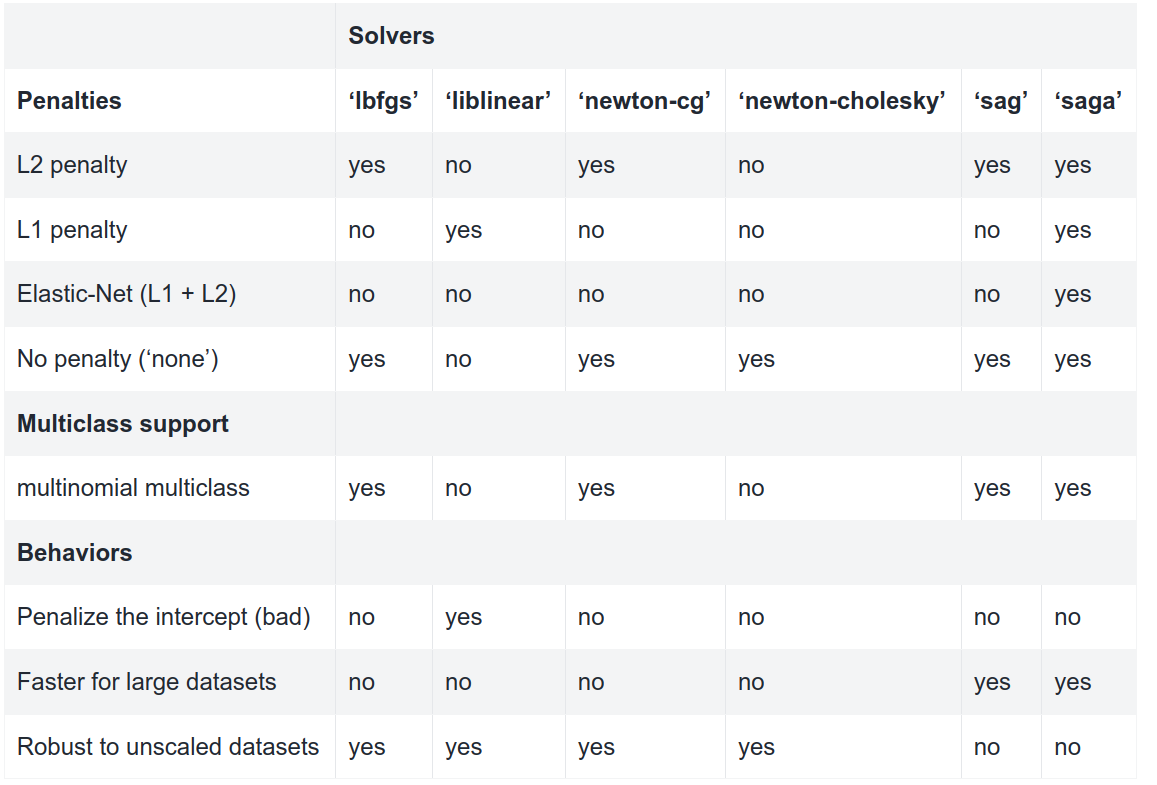

In [55]:
# instantiate the model (using the default parameters)
logreg = LogisticRegression(solver="lbfgs", class_weight = 'balanced') #if model input is large, try lbfgs which use less memroy
#solver: optimization method, out of the scope of this class

# fit the model with data
logreg.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [56]:
type(logreg) # python object

sklearn.linear_model._logistic.LogisticRegression

In [57]:
logreg

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


# how do you konw what is inside `logreg` object

In [63]:
logreg.__dict__ #['coef_']

{'penalty': 'l2',
 'dual': False,
 'tol': 0.0001,
 'C': 1.0,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'class_weight': 'balanced',
 'random_state': None,
 'solver': 'lbfgs',
 'max_iter': 100,
 'multi_class': 'deprecated',
 'verbose': 0,
 'warm_start': False,
 'n_jobs': None,
 'l1_ratio': None,
 'feature_names_in_': array(['Pregnancies', 'Glucose', 'BloodPressure', 'Insulin', 'BMI', 'Age'],
       dtype=object),
 'n_features_in_': 6,
 'classes_': array([0, 1]),
 'n_iter_': array([85], dtype=int32),
 'coef_': array([[ 0.12834343,  0.03259776, -0.01407771, -0.00077656,  0.10377459,
          0.01358226]]),
 'intercept_': array([-7.39577409])}

In [ ]:
#theta0, theta1 .....

In [ ]:
theta0 = -7.39577409
[theta1, theta2, theta3, theta4,heta5, heta6] = \
   [0.12834343,  0.03259776, -0.01407771, -0.00077656,  0.10377459,
          0.01358226]

## use python inbuilt function

In [51]:
# you will get from the Logistic Regression model is the model coefficients 

In [61]:
hasattr(logreg, "coef_")

True

In [32]:
getattr(logreg, "coef_")

array([[ 0.12776494,  0.03310541, -0.01298649, -0.00118092,  0.10348634,
         0.90859061,  0.01163796]])

In [31]:
logreg.coef_

array([[ 0.12776494,  0.03310541, -0.01298649, -0.00118092,  0.10348634,
         0.90859061,  0.01163796]])

# fit Logistic Regression model using different solvers

In [ ]:
# logreg1 = LogisticRegression(solver="lbfgs")
# logreg1.fit(X_train,y_train)

/home/dada/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

 # solution: increase iterations  

In [71]:
logreg1 = LogisticRegression(solver="lbfgs", max_iter = 1000, random_state= 1234,
                              class_weight = 'balanced') #default is max_iter=100
logreg1.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,1234
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [72]:
logreg1.coef_ #same as the newton-cg solver

array([[ 0.12834343,  0.03259776, -0.01407771, -0.00077656,  0.10377459,
         0.01358226]])

# Run prediction

In [ ]:
# make predictions
y_pred1=logreg1.predict(X_test)
#y_pred=logreg.predict(X_test)

In [74]:
y_pred1 #hard prediction

array([0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1])

In [93]:
y_prob1 =  logreg1.predict_proba(X_test)
#y_prob =  logreg.predict_proba(X_test)

In [97]:
y_prob1[:6]

array([[0.78950346, 0.21049654],
       [0.50955825, 0.49044175],
       [0.72229165, 0.27770835],
       [0.25842602, 0.74157398],
       [0.20861413, 0.79138587],
       [0.60447522, 0.39552478]])

In [88]:
y_prob[:6] # slight diffence

array([[0.70115442, 0.29884558],
       [0.90305935, 0.09694065],
       [0.84555242, 0.15444758],
       [0.8772801 , 0.1227199 ],
       [0.88480302, 0.11519698],
       [0.44650424, 0.55349576]])

In [ ]:
#y_hat compare with y_obs

 ### Model Evaluation using Confusion Matrix
A confusion matrix is a table that is used to evaluate the performance of a classification model. You can also visualize the performance of an algorithm. The fundamental of a confusion matrix is the number of correct and incorrect predictions are summed up class-wise.

In [78]:
# import the metrics class for classification performance evaluation
from sklearn import metrics
cnf_matrix = metrics.confusion_matrix(y_test, y_pred1)
cnf_matrix

array([[75, 25],
       [11, 43]])

In [79]:
# import the metrics class for classification performance evaluation
# from sklearn import metrics
# cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
# cnf_matrix

In [81]:
# import the metrics class for classification performance evaluation
from sklearn import metrics
cnf_matrix1 = metrics.confusion_matrix(y_test, y_pred1)
cnf_matrix1

array([[75, 25],
       [11, 43]])

In [48]:
import numpy as np

In [50]:
# calculate class prediction accuracy
sum(np.diag(cnf_matrix1))/sum(cnf_matrix1.reshape(-1)) #75%, not bad we have other approaches to deal with it cross-validation (CV)

0.7552083333333334

In [80]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred1))

              precision    recall  f1-score   support

           0       0.87      0.75      0.81       100
           1       0.63      0.80      0.70        54

    accuracy                           0.77       154
   macro avg       0.75      0.77      0.76       154
weighted avg       0.79      0.77      0.77       154



Here, you can see the confusion matrix in the form of the array object. The dimension of this matrix is 2*2 because this model is binary classification. You have two classes 0 and 1. Diagonal values represent accurate predictions, while non-diagonal elements are inaccurate predictions. In the output, 119 and 36 are actual predictions, and 26 and 11 are incorrect predictions.

## Visualizing Confusion Matrix using Heatmap module from SNS
Let's visualize the results of the model in the form of a confusion matrix using matplotlib and seaborn.

Here, you will visualize the confusion matrix using Heatmap.

In [85]:
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np

Text(0.5, 23.52222222222222, 'Predicted label')

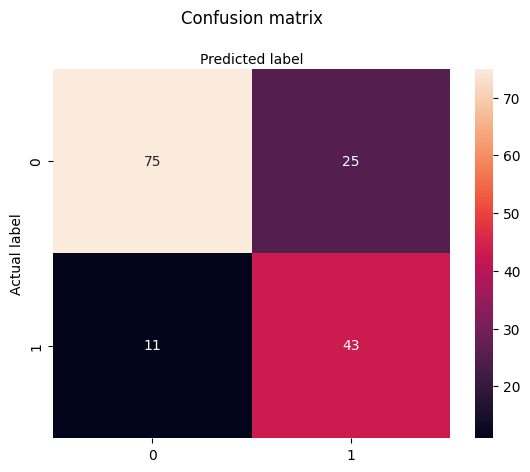

In [86]:
class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, fmt='g') #cmap="YlGnBu" ,
ax.xaxis.set_label_position("top")
# plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

 ##  get normalized matrix
 * https://seaborn.pydata.org/generated/seaborn.heatmap.html

Text(0.5, 23.52222222222222, 'Predicted label')

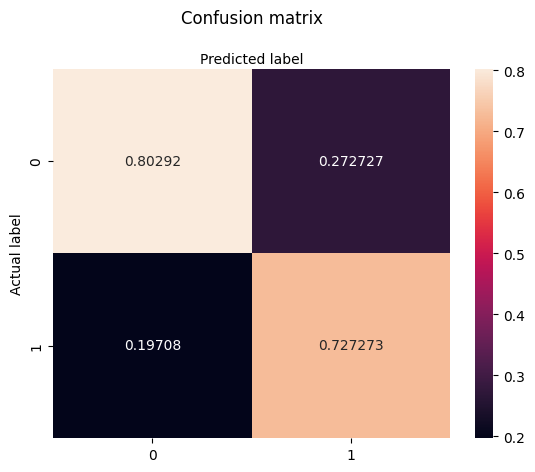

In [91]:
class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

# create normalized heatmap by column
df_norm = pd.DataFrame(cnf_matrix)
df_norm = df_norm.apply(lambda x: x/sum(x), axis = 0) #by column using axis = 0, remember the difference of numpy and pandas in axis definition!!! 

sns.heatmap(df_norm, annot=True, fmt='g') #cmap="YlGnBu" ,
ax.xaxis.set_label_position("top")
# plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

 # Why 0 class has higher prediction accuracy?
 * unbalance training data, class0:class1 is 2:1, What to do then?  
 

# Possible solution: 
1) upsample the minority class, e.g. using SMOTE; 
2) downsample the majority class, NOT favered

 ## Confusion Matrix Evaluation Metrics
Let's evaluate the model using model evaluation metrics such as accuracy, precision, and recall.

Let us watch a youtube video clip @ https://www.youtube.com/watch?v=y9jzatMS1VM

In [56]:
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))
print("Precision:",metrics.precision_score(y_test, y_pred))
print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 0.7552083333333334
Precision: 0.6219512195121951
Recall: 0.7611940298507462


* Well, you got a classification rate of ~ 78%, considered as good accuracy.

* Precision: Precision is about being precise, i.e., how accurate your model is. In other words, you can say, when a model makes a prediction, how often it is correct. In your prediction case, when your Logistic Regression model predicted patients are going to suffer from diabetes, that patients have 73% of the time.

* Recall: If there are patients who have diabetes in the test set and your Logistic Regression model can identify it 59% of the time.

*Task: Calculate all three matrices by yourself*

 # get classification summary

In [59]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.88      0.84       125
           1       0.73      0.60      0.66        67

    accuracy                           0.78       192
   macro avg       0.77      0.74      0.75       192
weighted avg       0.78      0.78      0.78       192



 ### With extremly imbalanced data, we also report F0.5 or F2, which are variants of Fbeta measure
 $$
  Fbeta = ((1 + beta^2) * Precision * Recall) / (beta^2 * Precision + Recall)
$$ 
 * F0.5-Measure (beta=0.5): More weight on precision, less weight on recall.
 * F1-Measure (beta=1.0): Balance the weight on precision and recall.
 * F2-Measure (beta=2.0): Less weight on precision, more weight on recall

 ### ROC Curve
The ROC curve was first used during World War II for the analysis of radar signals before it was employed in signal detection theory.
Receiver Operating Characteristic(ROC) curve is a plot of the true positive rate against the false positive rate.

Reference: https://towardsdatascience.com/understanding-auc-roc-curve-68b2303cc9c5   

 ## <center> ROC plot using <span style="color:red">probability</span> instead of prediciton of classification</center>

In [61]:
y_pred_proba1 = logreg1.predict_proba(X_test)[::,1] #get soft class or probs of 1

In [62]:
y_pred_proba1[:10]

array([0.13066586, 0.45483605, 0.17184883, 0.42950888, 0.23623465,
       0.73119763, 0.52102523, 0.48025302, 0.28770253, 0.46027545])

In [73]:
y_pred_cls1 =  logreg1.predict(X_test) #get hard class

# <font color = "red">DO NOT </font> use binary class prediction (hard class) for ROC plot 

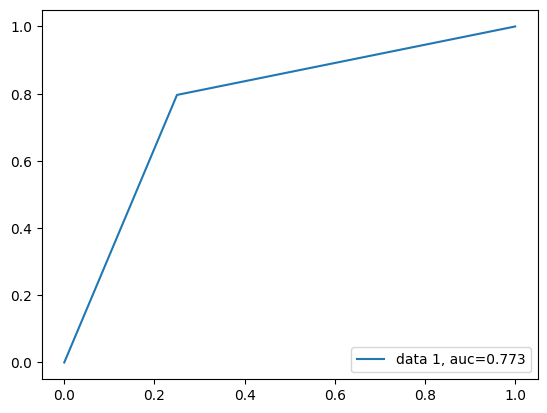

In [90]:
fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred1)
auc = metrics.roc_auc_score(y_test, y_pred1)
plt.plot(fpr,tpr,label="data 1, auc="+str(round(auc,3)))
plt.legend(loc=4)
plt.show()

# Instead use class probability for ROC plot  

In [57]:
y_test

190    0
533    0
760    0
318    0
528    0
      ..
334    0
57     0
320    0
374    0
708    1
Name: label, Length: 192, dtype: int64

In [105]:
y_prob1[:,1]

array([0.21049654, 0.49044175, 0.27770835, 0.74157398, 0.79138587,
       0.39552478, 0.70998118, 0.54280248, 0.57218616, 0.50950516,
       0.52997542, 0.30329352, 0.11206607, 0.22782978, 0.23213349,
       0.63554485, 0.69571965, 0.49168306, 0.46324637, 0.68501186,
       0.42197798, 0.5473862 , 0.15839881, 0.28788776, 0.08595949,
       0.82544905, 0.15894826, 0.17066766, 0.33509555, 0.98545893,
       0.92817316, 0.10835843, 0.87538883, 0.41337067, 0.88706258,
       0.20000644, 0.5732141 , 0.83163397, 0.07202494, 0.87437153,
       0.27765272, 0.73367222, 0.45802633, 0.93047225, 0.85722732,
       0.71879006, 0.27039256, 0.89359864, 0.64738063, 0.84762786,
       0.42045357, 0.13429478, 0.43104888, 0.51835425, 0.367427  ,
       0.0839036 , 0.75358351, 0.82913825, 0.47708412, 0.63160761,
       0.29257545, 0.69795034, 0.17082548, 0.11887278, 0.70094454,
       0.66192813, 0.46658403, 0.05154041, 0.48660445, 0.71653803,
       0.54492198, 0.63856447, 0.91175094, 0.84468794, 0.65024

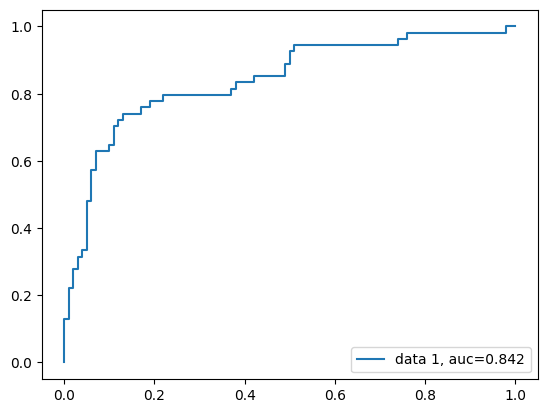

In [106]:
fpr, tpr, _ = metrics.roc_curve(y_test,  y_prob1[:,1])
auc = metrics.roc_auc_score(y_test, y_prob1[:,1])
plt.plot(fpr,tpr,label="data 1, auc="+str(round(auc,3)))
plt.legend(loc=4)
plt.show() #AUC : area under curve

AUC score for the case is 0.874. AUC score 1 represents perfect classifier, and 0.5 represents a worthless classifier.

# Appendix

## Logistic regression Example 2

## Data

Let’s use the `iris` dataset to illustrate Logistic Regression. This is a famous dataset that contains the sepal and petal length and width of 150 iris flowers of three different species: Iris-Setosa, Iris-Versicolor, and Iris-Virginica


In [2]:
from sklearn import datasets
iris = datasets.load_iris()

print(type(iris))

list(iris.keys())

# iris.data
# iris.target

<class 'sklearn.utils._bunch.Bunch'>


['data',
 'target',
 'frame',
 'target_names',
 'DESCR',
 'feature_names',
 'filename',
 'data_module']

In [92]:
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

    :Number of Instances: 150 (50 in each of three classes)
    :Number of Attributes: 4 numeric, predictive attributes and the class
    :Attribute Information:
        - sepal length in cm
        - sepal width in cm
        - petal length in cm
        - petal width in cm
        - class:
                - Iris-Setosa
                - Iris-Versicolour
                - Iris-Virginica
                
    :Summary Statistics:

    ============== ==== ==== ======= ===== ====================
                    Min  Max   Mean    SD   Class Correlation
    ============== ==== ==== ======= ===== ====================
    sepal length:   4.3  7.9   5.84   0.83    0.7826
    sepal width:    2.0  4.4   3.05   0.43   -0.4194
    petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
    petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
    ============== ==== ==== ======= ===== ===========

## Models

In [94]:
X = iris["data"][:, 3:]  # petal width
y = (iris["target"] == 2).astype(int)  # 1 if Iris-Virginica, else 0

In [95]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(solver="lbfgs", random_state=42)
log_reg.fit(X, y)
# we are done here~~~~

# solver="lbfgs" are part of the optimization method that is out of the scope of this class. 
# Pick the default ones when you encournter such case in the future.

LogisticRegression(random_state=42)

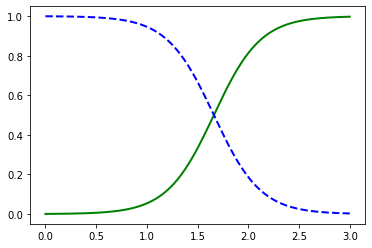

In [96]:
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)
y_proba = log_reg.predict_proba(X_new)

plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris-Virginica")
plt.plot(X_new, y_proba[:, 0], "b--", linewidth=2, label="Not Iris-Virginica")

C:\Users\DADA\anaconda3\lib\site-packages\matplotlib\patches.py:1338: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  verts = np.dot(coords, M) + (x + dx, y + dy)


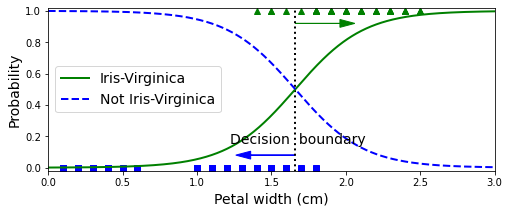

In [97]:
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:, 1] >= 0.5][0]

plt.figure(figsize=(8, 3))
plt.plot(X[y==0], y[y==0], "bs")
plt.plot(X[y==1], y[y==1], "g^")
plt.plot([decision_boundary, decision_boundary], [-1, 2], "k:", linewidth=2)
plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris-Virginica")
plt.plot(X_new, y_proba[:, 0], "b--", linewidth=2, label="Not Iris-Virginica")
plt.text(decision_boundary+0.02, 0.15, "Decision  boundary", fontsize=14, color="k", ha="center")
plt.arrow(decision_boundary, 0.08, -0.3, 0, head_width=0.05, head_length=0.1, fc='b', ec='b')
plt.arrow(decision_boundary, 0.92, 0.3, 0, head_width=0.05, head_length=0.1, fc='g', ec='g')
plt.xlabel("Petal width (cm)", fontsize=14)
plt.ylabel("Probability", fontsize=14)
plt.legend(loc="center left", fontsize=14)
plt.axis([0, 3, -0.02, 1.02])
plt.show()

In [98]:
decision_boundary

array([1.66066066])

In [99]:
log_reg.predict([[1.7], [1.5]])

array([1, 0])

# Sigmoid vs Softmax

### Softmax Regression

The Logistic Regression model can be generalized to support multiple classes directly,
without having to train and combine multiple binary classifiers (as discussed in
Chapter 3). This is called Softmax Regression, or Multinomial Logistic Regression.  

The idea is quite simple: when given an instance x, the Softmax Regression model
first computes a score sk(x) for each class k, then estimates the probability of each
class by applying the softmax function (also called the normalized exponential) to the
scores. The equation to compute sk(x) should look familiar, as it is just like the equation
for Linear Regression prediction

**Softmax score for class k**

$
s_k(\mathbf{x}) = ({\boldsymbol{\theta}^{(k)}})^T \mathbf{x}
$


**Softmax function**

$
\hat{p}_k = \sigma\left(\mathbf{s}(\mathbf{x})\right)_k = \dfrac{\exp\left(s_k(\mathbf{x})\right)}{\sum\limits_{j=1}^{K}{\exp\left(s_j(\mathbf{x})\right)}}
$

Just like the Logistic Regression classifier, the Softmax Regression classifier predicts
the class with the highest estimated probability (which is simply the class with the
highest score), as shown in

**Softmax Regression classifier prediction**

$
\hat{y} = \underset{k}{\operatorname{argmax}} \, \sigma\left(\mathbf{s}(\mathbf{x})\right)_k = \underset{k}{\operatorname{argmax}} \, s_k(\mathbf{x}) = \underset{k}{\operatorname{argmax}} \, \left( ({\boldsymbol{\theta}^{(k)}})^T \mathbf{x} \right)
$

## Cross entropy
**Cross entropy cost function**

$
J(\boldsymbol{\Theta}) = - \dfrac{1}{m}\sum\limits_{i=1}^{m}\sum\limits_{k=1}^{K}{y_k^{(i)}\log\left(\hat{p}_k^{(i)}\right)}
$

**Cross entropy between two discrete probability distributions $p$ and $q$ (page 141):**
$ H(p, q) = -\sum\limits_{x}p(x) \log q(x) $


**Cross entropy gradient vector for class _k_**

$
\nabla_{\boldsymbol{\theta}^{(k)}} \, J(\boldsymbol{\Theta}) = \dfrac{1}{m} \sum\limits_{i=1}^{m}{ \left ( \hat{p}^{(i)}_k - y_k^{(i)} \right ) \mathbf{x}^{(i)}}
$

In [100]:
X = iris["data"][:, (2, 3)]  # petal length, petal width
y = iris["target"]

softmax_reg = LogisticRegression(multi_class="multinomial",solver="lbfgs", C=10, random_state=42)
softmax_reg.fit(X, y)

LogisticRegression(C=10, multi_class='multinomial', random_state=42)

In [101]:
x0, x1 = np.meshgrid(
        np.linspace(0, 8, 500).reshape(-1, 1),
        np.linspace(0, 3.5, 200).reshape(-1, 1),
    )
X_new = np.c_[x0.ravel(), x1.ravel()]


y_proba = softmax_reg.predict_proba(X_new)
y_predict = softmax_reg.predict(X_new)

zz1 = y_proba[:, 1].reshape(x0.shape)
zz = y_predict.reshape(x0.shape)


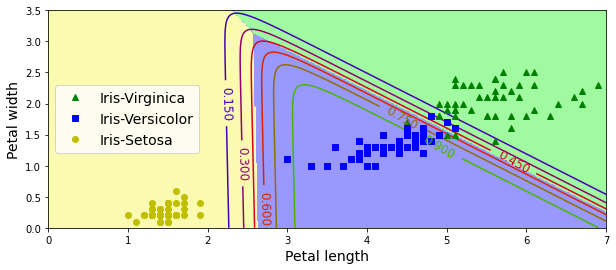

In [102]:

plt.figure(figsize=(10, 4))
plt.plot(X[y==2, 0], X[y==2, 1], "g^", label="Iris-Virginica")
plt.plot(X[y==1, 0], X[y==1, 1], "bs", label="Iris-Versicolor")
plt.plot(X[y==0, 0], X[y==0, 1], "yo", label="Iris-Setosa")
from matplotlib.colors import ListedColormap
custom_cmap = ListedColormap(['#fafab0','#9898ff','#a0faa0'])

plt.contourf(x0, x1, zz, cmap=custom_cmap)
contour = plt.contour(x0, x1, zz1, cmap=plt.cm.brg)
plt.clabel(contour, inline=1, fontsize=12)
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.legend(loc="center left", fontsize=14)
plt.axis([0, 7, 0, 3.5])
plt.show()

In [103]:
softmax_reg.predict([[5, 2]])

array([2])

In [104]:
softmax_reg.predict_proba([[5, 2]])

array([[6.38014896e-07, 5.74929995e-02, 9.42506362e-01]])



#### Least Squares Line

$$\hat{y} = a + bx$$

where 

$$b = \frac {{SS}_{xy}}{{SS}_{xx}}$$

and 

$$\bar{y} = a + b\bar{x}$$



#### Standard Errors
$$s_{e} = \sqrt \frac {SSResid}{n - 2}$$

$$s_{b} = \frac {s_{e}}{\sqrt {{SS}_{xx}}}$$

$$s_{a + bx} = s_{e} \sqrt {1 + \frac {1}{n} + \frac {(x - \bar{x})^2}{{SS}_{xx}}}$$

for prediction:

$$se(y - \hat{y}) = s_{e} \sqrt {1 + \frac {1}{n} + \frac {(x - \bar{x})^2}{{SS}_{xx}}}$$



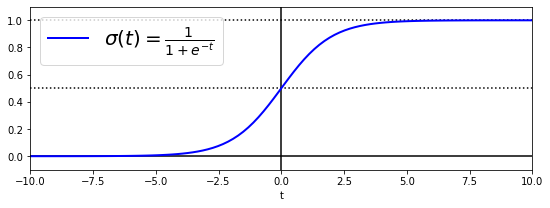

In [105]:
#Logistic (sigmoid) function
t = np.linspace(-10, 10, 100)
sig = 1 / (1 + np.exp(-t))
plt.figure(figsize=(9, 3))
plt.plot([-10, 10], [0, 0], "k-")
plt.plot([-10, 10], [0.5, 0.5], "k:")
plt.plot([-10, 10], [1, 1], "k:")
plt.plot([0, 0], [-1.1, 1.1], "k-")
plt.plot(t, sig, "b-", linewidth=2, label=r"$\sigma(t) = \frac{1}{1 + e^{-t}}$")
plt.xlabel("t")
plt.legend(loc="upper left", fontsize=20)
plt.axis([-10, 10, -0.1, 1.1])
plt.show()

## Linear Regression model (Machine Learning method)

In [106]:
from IPython.display import IFrame
IFrame(src='https://scikit-learn.org/stable/', width=1000, height=600)

In [107]:
# Step 1: data (with random noises) generation
np.random.seed(7) # to make this notebook's output stable across runs
nsample = 200
X = 2 * np.random.rand(nsample, 1)
y = 4 + 3 * X + np.random.randn(nsample, 1)
X_b = np.c_[np.ones((nsample, 1)), X]  # add x0 = 1 to each instance
X_new = np.array([0,2])
X_new_b = np.c_[np.ones((2, 1)), X_new]  # add x0 = 1 to each instance

In [108]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X, y)
lin_reg.intercept_, lin_reg.coef_

(array([4.01777976]), array([[2.95206276]]))

The `LinearRegression` class is based on the `scipy.linalg.lstsq()` function (the name stands for "least squares"), which you could call directly:

In [109]:
theta_best_svd, residuals, rank, s = np.linalg.lstsq(X_b, y, rcond=1e-6)
theta_best_svd

array([[4.01777976],
       [2.95206276]])

# Linear regression using batch gradient descent

Better Suite large numbers of features ("Xn")

In [110]:
eta = 0.1  # learning rate
n_iterations = 1000
m = 100   # Sample size
theta = np.random.randn(2,1)

for iteration in range(n_iterations):
    gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y)
    theta = theta - eta * gradients

In [111]:
theta

array([[4.01777976],
       [2.95206276]])

In [112]:
X_new_b.dot(theta)

array([[4.01777976],
       [9.92190528]])

#### Gradient Descent


<img src="Inputs/Gradient_Descent.PNG" alt="Kitten" width="850" height="600" />




```python
eta = 0.1  # learning rate
for iteration in range(n_iterations):
    gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y)
    theta = theta - eta * gradients
```

In this particular case


**Partial derivatives of the cost function**

$
\dfrac{\partial}{\partial \theta_j} \text{MSE}(\boldsymbol{\theta}) = \dfrac{2}{m}\sum\limits_{i=1}^{m}(\boldsymbol{\theta}^T \mathbf{x}^{(i)} - y^{(i)})\, x_j^{(i)}
$

(To save time, the derivation of the equation is omitted from this class)

#### Choosing the optimal "Learning Rate" is key to train the model

In [113]:
theta_path_bgd = []

def plot_gradient_descent(theta, eta, theta_path=None):
    m = len(X_b)
    plt.plot(X, y, "b.")
    n_iterations = 1000
    for iteration in range(n_iterations):
        if iteration < 10:
            y_predict = X_new_b.dot(theta)
            style = "b-" if iteration > 0 else "r--"
            plt.plot(X_new, y_predict, style)
        gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y)
        theta = theta - eta * gradients
        if theta_path is not None:
            theta_path.append(theta)
    plt.xlabel("$x_1$", fontsize=18)
    plt.axis([0, 2, 0, 15])
    plt.title(r"$\eta = {}$".format(eta), fontsize=16)

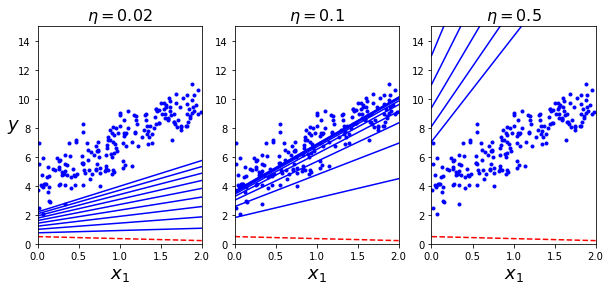

In [114]:
np.random.seed(42)
theta = np.random.randn(2,1)  # random initialization

plt.figure(figsize=(10,4))
plt.subplot(131); plot_gradient_descent(theta, eta=0.02)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.subplot(132); plot_gradient_descent(theta, eta=0.1, theta_path=theta_path_bgd)
plt.subplot(133); plot_gradient_descent(theta, eta=0.5)

plt.show()

When using Gradient Descent approach, you should ensure that all features
have a similar scale (e.g., using Scikit-Learn’s StandardScaler
class), or else it will take much longer to converge.

# Stochastic Gradient Descent

The main problem with Batch Gradient Descent is the fact that it uses the whole
training set to compute the gradients at every step, which makes it very slow when
the training set is large. At the opposite extreme, Stochastic Gradient Descent just
picks a random instance in the training set at every step and computes the gradients
based only on that single instance. Obviously this makes the algorithm much faster
since it has very little data to manipulate at every iteration. It also makes it possible to
train on huge training sets, since only one instance needs to be in memory at each
iteration (SGD can be implemented as an out-of-core algorithm.)

On the other hand, due to its stochastic (i.e., random) nature, this algorithm is much
less regular than Batch Gradient Descent: instead of gently decreasing until it reaches
the minimum, the cost function will bounce up and down, decreasing only on average.
Over time it will end up very close to the minimum, but once it gets there it will
continue to bounce around, never settling down (see Figure below). So once the algorithm
stops, the final parameter values are good, but not optimal.

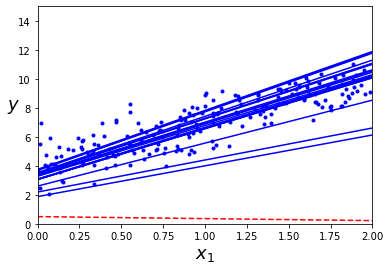

In [115]:
# Simulated Annealing
# This code implements Stochastic Gradient Descent using a simple learning schedule:

theta_path_sgd = []
m = len(X_b)
np.random.seed(42)

n_epochs = 50
t0, t1 = 5, 50  # learning schedule hyperparameters

def learning_schedule(t):
    return t0 / (t + t1)

theta = np.random.randn(2,1)  # random initialization

for epoch in range(n_epochs):
    for i in range(m):
        if epoch == 0 and i < 20:                    # not shown in the book
            y_predict = X_new_b.dot(theta)           # not shown
            style = "b-" if i > 0 else "r--"         # not shown
            plt.plot(X_new, y_predict, style)        # not shown
        random_index = np.random.randint(m)
        xi = X_b[random_index:random_index+1]
        yi = y[random_index:random_index+1]
        gradients = 2 * xi.T.dot(xi.dot(theta) - yi)
        eta = learning_schedule(epoch * m + i)
        theta = theta - eta * gradients
        theta_path_sgd.append(theta)                 # not shown

plt.plot(X, y, "b.")                                 # not shown
plt.xlabel("$x_1$", fontsize=18)                     # not shown
plt.ylabel("$y$", rotation=0, fontsize=18)           # not shown
plt.axis([0, 2, 0, 15])                              # not shown
plt.show()                                           # not shown

In [116]:
theta

array([[4.00874955],
       [2.97040337]])

perform Linear Regression using SGD with Scikit-Learn

In [117]:
from sklearn.linear_model import SGDRegressor
sgd_reg = SGDRegressor(max_iter=50, tol=-np.infty, penalty=None, eta0=0.1, random_state=42)
sgd_reg.fit(X, y.ravel())
sgd_reg.intercept_, sgd_reg.coef_

(array([4.00435375]), array([2.93487361]))

# Mini-batch gradient descent

At each step, instead of computing the gradients based on the full training
set (as in Batch GD) or based on just one instance (as in Stochastic GD), Mini-
batch GD computes the gradients on small random sets of instances called minibatches.
The main advantage of Mini-batch GD over Stochastic GD is that you can
get a performance boost from hardware optimization of matrix operations, especially
when using GPUs.

In [118]:
theta_path_mgd = []

n_iterations = 50
minibatch_size = 20

np.random.seed(42)
theta = np.random.randn(2,1)  # random initialization

t0, t1 = 200, 1000
def learning_schedule(t):
    return t0 / (t + t1)

t = 0
for epoch in range(n_iterations):
    shuffled_indices = np.random.permutation(m)
    X_b_shuffled = X_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]
    for i in range(0, m, minibatch_size):
        t += 1
        xi = X_b_shuffled[i:i+minibatch_size]
        yi = y_shuffled[i:i+minibatch_size]
        gradients = 2/minibatch_size * xi.T.dot(xi.dot(theta) - yi)
        eta = learning_schedule(t)
        theta = theta - eta * gradients
        theta_path_mgd.append(theta)

In [119]:
theta

array([[4.14108659],
       [3.10829591]])

In [120]:
theta_path_bgd = np.array(theta_path_bgd)
theta_path_sgd = np.array(theta_path_sgd)
theta_path_mgd = np.array(theta_path_mgd)

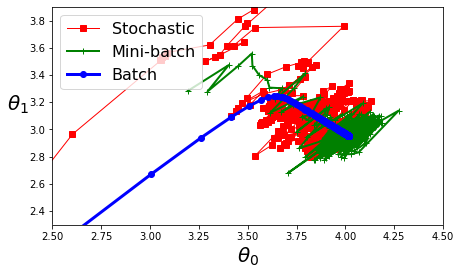

In [121]:
plt.figure(figsize=(7,4))
plt.plot(theta_path_sgd[:, 0], theta_path_sgd[:, 1], "r-s", linewidth=1, label="Stochastic")
plt.plot(theta_path_mgd[:, 0], theta_path_mgd[:, 1], "g-+", linewidth=2, label="Mini-batch")
plt.plot(theta_path_bgd[:, 0], theta_path_bgd[:, 1], "b-o", linewidth=3, label="Batch")
plt.legend(loc="upper left", fontsize=16)
plt.xlabel(r"$\theta_0$", fontsize=20)
plt.ylabel(r"$\theta_1$   ", fontsize=20, rotation=0)
plt.axis([2.5, 4.5, 2.3, 3.9])
plt.show()

# Polynomial regression

In [122]:
import numpy as np
import numpy.random as rnd

np.random.seed(7)

In [123]:
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X**2 + X + 2 + np.random.randn(m, 1)

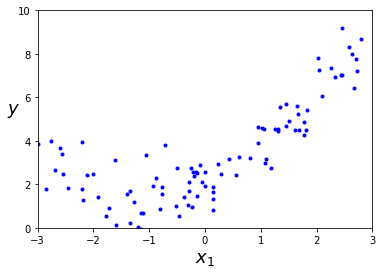

In [124]:
plt.plot(X, y, "b.")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.axis([-3, 3, 0, 10])
plt.show()

In [125]:
from sklearn.preprocessing import PolynomialFeatures
poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_features.fit_transform(X)
X[0]

array([-2.54215026])

In [126]:
X_poly[0]

array([-2.54215026,  6.46252796])

In [127]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)
lin_reg.intercept_, lin_reg.coef_

(array([2.00725434]), array([[1.05076701, 0.49607621]]))

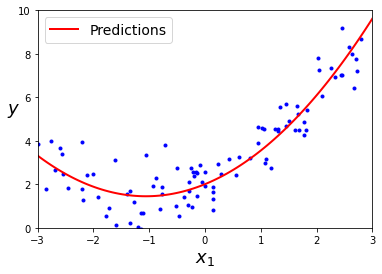

In [128]:
X_new=np.linspace(-3, 3, 100).reshape(100, 1)
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)
plt.plot(X, y, "b.")
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.legend(loc="upper left", fontsize=14)
plt.axis([-3, 3, 0, 10])
plt.show()

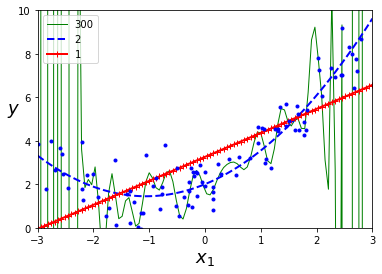

In [129]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

for style, width, degree in (("g-", 1, 300), ("b--", 2, 2), ("r-+", 2, 1)):
    polybig_features = PolynomialFeatures(degree=degree, include_bias=False)
    std_scaler = StandardScaler()
    lin_reg = LinearRegression()
    polynomial_regression = Pipeline([
            ("poly_features", polybig_features),
            ("std_scaler", std_scaler),
            ("lin_reg", lin_reg),
        ])
    polynomial_regression.fit(X, y)
    y_newbig = polynomial_regression.predict(X_new)
    plt.plot(X_new, y_newbig, style, label=str(degree), linewidth=width)

plt.plot(X, y, "b.", linewidth=3)
plt.legend(loc="upper left")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.axis([-3, 3, 0, 10])
plt.show()

In [130]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

def plot_learning_curves(model, X, y):
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=10)
    train_errors, val_errors = [], []
    for m in range(1, len(X_train)):
        model.fit(X_train[:m], y_train[:m])
        y_train_predict = model.predict(X_train[:m])
        y_val_predict = model.predict(X_val)
        train_errors.append(mean_squared_error(y_train[:m], y_train_predict))
        val_errors.append(mean_squared_error(y_val, y_val_predict))

    plt.plot(np.sqrt(train_errors), "r-+", linewidth=2, label="train")
    plt.plot(np.sqrt(val_errors), "b-", linewidth=3, label="val")
    plt.legend(loc="upper right", fontsize=14)   # not shown in the book
    plt.xlabel("Training set size", fontsize=14) # not shown
    plt.ylabel("RMSE", fontsize=14)              # not shown

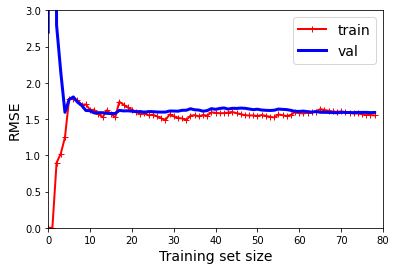

In [131]:
lin_reg = LinearRegression()
plot_learning_curves(lin_reg, X, y)
plt.axis([0, 80, 0, 3])                         # not shown in the book
plt.show()                                      # not shown

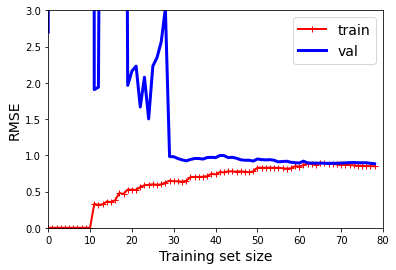

In [132]:
from sklearn.pipeline import Pipeline

polynomial_regression = Pipeline([
        ("poly_features", PolynomialFeatures(degree=10, include_bias=False)),
        ("lin_reg", LinearRegression()),
    ])

plot_learning_curves(polynomial_regression, X, y)
plt.axis([0, 80, 0, 3])           # not shown
plt.show()                        # not shown

# Regularized models

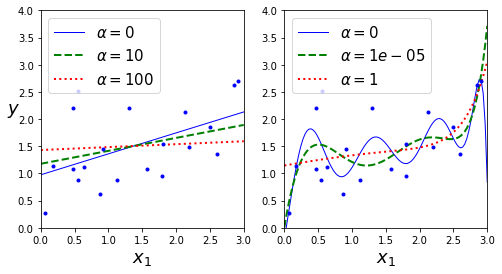

In [133]:
from sklearn.linear_model import Ridge

np.random.seed(42)
m = 20
X = 3 * np.random.rand(m, 1)
y = 1 + 0.5 * X + np.random.randn(m, 1) / 1.5
X_new = np.linspace(0, 3, 100).reshape(100, 1)

def plot_model(model_class, polynomial, alphas, **model_kargs):
    for alpha, style in zip(alphas, ("b-", "g--", "r:")):
        model = model_class(alpha, **model_kargs) if alpha > 0 else LinearRegression()
        if polynomial:
            model = Pipeline([
                    ("poly_features", PolynomialFeatures(degree=10, include_bias=False)),
                    ("std_scaler", StandardScaler()),
                    ("regul_reg", model),
                ])
        model.fit(X, y)
        y_new_regul = model.predict(X_new)
        lw = 2 if alpha > 0 else 1
        plt.plot(X_new, y_new_regul, style, linewidth=lw, label=r"$\alpha = {}$".format(alpha))
    plt.plot(X, y, "b.", linewidth=3)
    plt.legend(loc="upper left", fontsize=15)
    plt.xlabel("$x_1$", fontsize=18)
    plt.axis([0, 3, 0, 4])

plt.figure(figsize=(8,4))
plt.subplot(121)
plot_model(Ridge, polynomial=False, alphas=(0, 10, 100), random_state=42)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.subplot(122)
plot_model(Ridge, polynomial=True, alphas=(0, 10**-5, 1), random_state=42)

plt.show()

### Ridge Regression
Ridge Regression (also called Tikhonov regularization) is a regularized version of Linear
Regression: a regularization term equal to $ \dfrac{1}{2} \alpha \sum\limits_{i=1}^{n}{\theta_i}^2$  is added to the cost function.
This forces the learning algorithm to not only fit the data but also keep the model
weights as small as possible. Note that the regularization term should only be added
to the cost function during training. Once the model is trained, you want to evaluate
the model’s performance using the unregularized performance measure.

**Ridge Regression penalty/cost function**

$
J(\boldsymbol{\theta}) = \text{MSE}(\boldsymbol{\theta}) +  \dfrac{1}{2}\alpha\sum\limits_{i=1}^{n}{\theta_i}^2
$


In [134]:
from sklearn.linear_model import Ridge
ridge_reg = Ridge(alpha=1, solver="cholesky", random_state=42)
ridge_reg.fit(X, y)
ridge_reg.predict([[1.5]])

array([[1.55071465]])

In [135]:
sgd_reg = SGDRegressor(max_iter=50, tol=-np.infty, penalty="l2", random_state=42)
sgd_reg.fit(X, y.ravel())
sgd_reg.predict([[1.5]])

array([1.49905184])

In [136]:
ridge_reg = Ridge(alpha=1, solver="sag", random_state=42)
ridge_reg.fit(X, y)
ridge_reg.predict([[1.5]])

array([[1.5507201]])

### Lasso Regression
Least Absolute Shrinkage and Selection Operator Regression (simply called Lasso
Regression) is another regularized version of Linear Regression: just like Ridge
Regression, it adds a regularization term to the cost function, but it uses the ℓ1 norm
of the weight vector instead of half the square of the ℓ2 norm (see Equation below).

**Lasso Regression cost function**

$
J(\boldsymbol{\theta}) = \text{MSE}(\boldsymbol{\theta}) + \alpha \sum\limits_{i=1}^{n}\left| \theta_i \right|
$


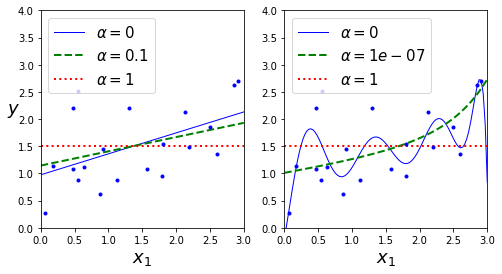

In [137]:
from sklearn.linear_model import Lasso

plt.figure(figsize=(8,4))
plt.subplot(121)
plot_model(Lasso, polynomial=False, alphas=(0, 0.1, 1), random_state=42)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.subplot(122)
plot_model(Lasso, polynomial=True, alphas=(0, 10**-7, 1), tol=1, random_state=42)
plt.show()

In [138]:
from sklearn.linear_model import Lasso
lasso_reg = Lasso(alpha=0.1)
lasso_reg.fit(X, y)
lasso_reg.predict([[1.5]])

array([1.53788174])

### ElasticNet

In [139]:
from sklearn.linear_model import ElasticNet
elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42)
elastic_net.fit(X, y)
elastic_net.predict([[1.5]])

array([1.54333232])

### Early Stopping

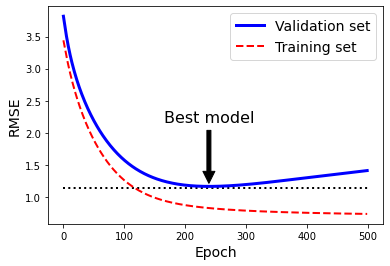

In [140]:
np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 2 + X + 0.5 * X**2 + np.random.randn(m, 1)

X_train, X_val, y_train, y_val = train_test_split(X[:50], y[:50].ravel(), test_size=0.5, random_state=10)

poly_scaler = Pipeline([
        ("poly_features", PolynomialFeatures(degree=90, include_bias=False)),
        ("std_scaler", StandardScaler()),
    ])

X_train_poly_scaled = poly_scaler.fit_transform(X_train)
X_val_poly_scaled = poly_scaler.transform(X_val)

sgd_reg = SGDRegressor(max_iter=1,
                       tol=-np.infty,
                       penalty=None,
                       eta0=0.0005,
                       warm_start=True,
                       learning_rate="constant",
                       random_state=42)

n_epochs = 500
train_errors, val_errors = [], []
for epoch in range(n_epochs):
    sgd_reg.fit(X_train_poly_scaled, y_train)
    y_train_predict = sgd_reg.predict(X_train_poly_scaled)
    y_val_predict = sgd_reg.predict(X_val_poly_scaled)
    train_errors.append(mean_squared_error(y_train, y_train_predict))
    val_errors.append(mean_squared_error(y_val, y_val_predict))

best_epoch = np.argmin(val_errors)
best_val_rmse = np.sqrt(val_errors[best_epoch])

plt.annotate('Best model',
             xy=(best_epoch, best_val_rmse),
             xytext=(best_epoch, best_val_rmse + 1),
             ha="center",
             arrowprops=dict(facecolor='black', shrink=0.05),
             fontsize=16,
            )

best_val_rmse -= 0.03  # just to make the graph look better
plt.plot([0, n_epochs], [best_val_rmse, best_val_rmse], "k:", linewidth=2)
plt.plot(np.sqrt(val_errors), "b-", linewidth=3, label="Validation set")
plt.plot(np.sqrt(train_errors), "r--", linewidth=2, label="Training set")
plt.legend(loc="upper right", fontsize=14)
plt.xlabel("Epoch", fontsize=14)
plt.ylabel("RMSE", fontsize=14)
plt.show()

In [141]:
from sklearn.base import clone
sgd_reg = SGDRegressor(max_iter=1, tol=-np.infty, warm_start=True, penalty=None,
                       learning_rate="constant", eta0=0.0005, random_state=42)

minimum_val_error = float("inf")
best_epoch = None
best_model = None
for epoch in range(1000):
    sgd_reg.fit(X_train_poly_scaled, y_train)  # continues where it left off
    y_val_predict = sgd_reg.predict(X_val_poly_scaled)
    val_error = mean_squared_error(y_val, y_val_predict)
    if val_error < minimum_val_error:
        minimum_val_error = val_error
        best_epoch = epoch
        best_model = clone(sgd_reg)

In [142]:
best_epoch, best_model

(239,
 SGDRegressor(eta0=0.0005, learning_rate='constant', max_iter=1, penalty=None,
              random_state=42, tol=-inf, warm_start=True))

In [143]:
t1a, t1b, t2a, t2b = -1, 3, -1.5, 1.5

# ignoring bias term
t1s = np.linspace(t1a, t1b, 500)
t2s = np.linspace(t2a, t2b, 500)
t1, t2 = np.meshgrid(t1s, t2s)
T = np.c_[t1.ravel(), t2.ravel()]
Xr = np.array([[-1, 1], [-0.3, -1], [1, 0.1]])
yr = 2 * Xr[:, :1] + 0.5 * Xr[:, 1:]

J = (1/len(Xr) * np.sum((T.dot(Xr.T) - yr.T)**2, axis=1)).reshape(t1.shape)

N1 = np.linalg.norm(T, ord=1, axis=1).reshape(t1.shape)
N2 = np.linalg.norm(T, ord=2, axis=1).reshape(t1.shape)

t_min_idx = np.unravel_index(np.argmin(J), J.shape)
t1_min, t2_min = t1[t_min_idx], t2[t_min_idx]

t_init = np.array([[0.25], [-1]])

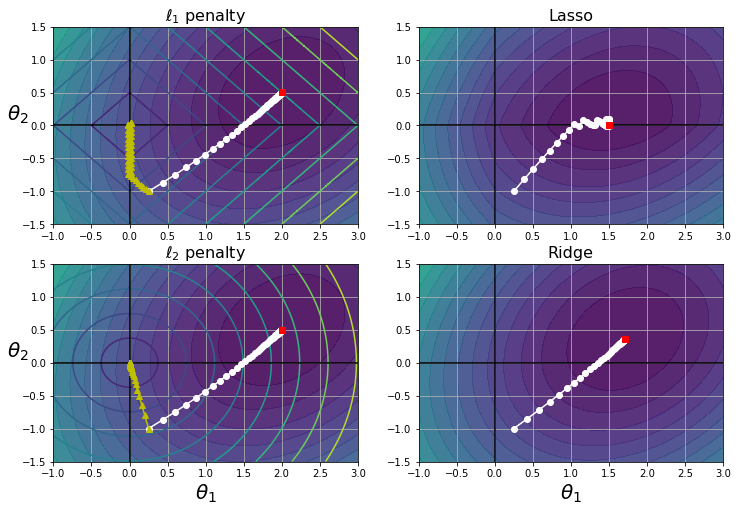

In [144]:
def bgd_path(theta, X, y, l1, l2, core = 1, eta = 0.1, n_iterations = 50):
    path = [theta]
    for iteration in range(n_iterations):
        gradients = core * 2/len(X) * X.T.dot(X.dot(theta) - y) + l1 * np.sign(theta) + 2 * l2 * theta

        theta = theta - eta * gradients
        path.append(theta)
    return np.array(path)

plt.figure(figsize=(12, 8))
for i, N, l1, l2, title in ((0, N1, 0.5, 0, "Lasso"), (1, N2, 0,  0.1, "Ridge")):
    JR = J + l1 * N1 + l2 * N2**2
    
    tr_min_idx = np.unravel_index(np.argmin(JR), JR.shape)
    t1r_min, t2r_min = t1[tr_min_idx], t2[tr_min_idx]

    levelsJ=(np.exp(np.linspace(0, 1, 20)) - 1) * (np.max(J) - np.min(J)) + np.min(J)
    levelsJR=(np.exp(np.linspace(0, 1, 20)) - 1) * (np.max(JR) - np.min(JR)) + np.min(JR)
    levelsN=np.linspace(0, np.max(N), 10)
    
    path_J = bgd_path(t_init, Xr, yr, l1=0, l2=0)
    path_JR = bgd_path(t_init, Xr, yr, l1, l2)
    path_N = bgd_path(t_init, Xr, yr, np.sign(l1)/3, np.sign(l2), core=0)

    plt.subplot(221 + i * 2)
    plt.grid(True)
    plt.axhline(y=0, color='k')
    plt.axvline(x=0, color='k')
    plt.contourf(t1, t2, J, levels=levelsJ, alpha=0.9)
    plt.contour(t1, t2, N, levels=levelsN)
    plt.plot(path_J[:, 0], path_J[:, 1], "w-o")
    plt.plot(path_N[:, 0], path_N[:, 1], "y-^")
    plt.plot(t1_min, t2_min, "rs")
    plt.title(r"$\ell_{}$ penalty".format(i + 1), fontsize=16)
    plt.axis([t1a, t1b, t2a, t2b])
    if i == 1:
        plt.xlabel(r"$\theta_1$", fontsize=20)
    plt.ylabel(r"$\theta_2$", fontsize=20, rotation=0)

    plt.subplot(222 + i * 2)
    plt.grid(True)
    plt.axhline(y=0, color='k')
    plt.axvline(x=0, color='k')
    plt.contourf(t1, t2, JR, levels=levelsJR, alpha=0.9)
    plt.plot(path_JR[:, 0], path_JR[:, 1], "w-o")
    plt.plot(t1r_min, t2r_min, "rs")
    plt.title(title, fontsize=16)
    plt.axis([t1a, t1b, t2a, t2b])
    if i == 1:
        plt.xlabel(r"$\theta_1$", fontsize=20)

plt.show()

In [145]:
# Importing the libraries
import sklearn


In [146]:
# Logistic Regression

# Importing the dataset
dataset = pd.read_csv('./References/P14-Logistic-Regression/Logistic_Regression/Social_Network_Ads.csv')
X = dataset.iloc[:, [2, 3]].values
y = dataset.iloc[:, 4].values

# Splitting the dataset into the Training set and Test set
from sklearn.model_selection  import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)

# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# Fitting Logistic Regression to the Training set
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)

# Predicting the Test set results
y_pred = classifier.predict(X_test)

# Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2-D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2-D array with a single row if you intend to specify the same RGB or RGBA value for all points.


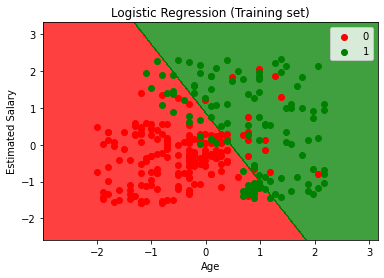

In [147]:
# Visualising the Training set results
from matplotlib.colors import ListedColormap
X_set, y_set = X_train, y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))
plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = ListedColormap(('red', 'green'))(i), label = j)
plt.title('Logistic Regression (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2-D array with a single row if you intend to specify the same RGB or RGBA value for all points.
*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2-D array with a single row if you intend to specify the same RGB or RGBA value for all points.


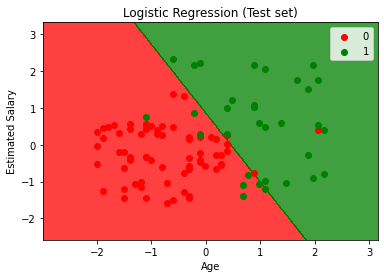

In [148]:
# Visualising the Test set results
from matplotlib.colors import ListedColormap
X_set, y_set = X_test, y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))
plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = ListedColormap(('red', 'green'))(i), label = j)
plt.title('Logistic Regression (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

### F-statistic

The alternative hypothesis is that at least one of the regression coefficients should be non-zero. 

$$F = \frac{R^2/p}{(1-R^2)/(n-p)} = \frac{explained\ variation/p}{(unexplained\  variation)/(n-p)}$$

In [149]:
import scipy

N = result.nobs
P = result.df_model
dfn, dfd = P, N - P - 1
F = result.mse_model / result.mse_resid

# F2 = r_square/P/(1-r_square)*(N-P)
p = 1.0 - scipy.stats.f.cdf(F,dfn,dfd)
print ('F-statistic: {:.3f},  p-value: {:.5f}'.format( F, p )) 

# because the p-value is less than 0.001, we reject null hypothesis that all regression coefficents are equal to zero 
# at significance level of 0.001.

F-statistic: 620.785,  p-value: 0.00000
